# Model: S&P 500 stock price prediction (tomorrow's close)
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [S&P 500 stock data (Kaggle, camnugent)](https://www.kaggle.com/camnugent/sandp500) — file `all_stocks_5yr.csv` | **Type:** regression (time series, 505 stocks)

One global model for all stocks, ready for the API (`models/stocks.joblib` + `predictors/stocks.py`).

Voice command: *"JarvisTEC, price of Apple stock"*

## 1. Problem analysis (0.5 pt)

**What do we want to predict?** The closing price (USD) of the next business day of an S&P 500 stock, to answer commands such as *"JarvisTEC, price of Apple stock"*.

**Why is it hard?** Stock prices are a classic example of almost unpredictable series: according to the efficient market hypothesis (Fama, 1970) prices already reflect past information. Recent studies applying ML to thousands of stocks find a very small predictive signal (Gu, Kelly and Xiu, 2020), and works with LSTM networks on S&P 500 stocks report modest advantages that depend on the period (Fischer and Krauss, 2018). That is why every model is compared against the **naive baseline** *"tomorrow = today"* (Hyndman and Athanasopoulos, 2021).

**Design decisions**
- **One global (*pooled*) model** for the 505 stocks instead of 505 small models: it provides ~600,000 observations, it is a single file for the API and it allows predicting any stock.
- **Target variable:** the *log return* of the next day, `ln(close_t+1 / close_t)`. Being a relative value, it is comparable between \$2 and \$2,000 stocks and avoids having the trees extrapolate prices. The price is rebuilt as `close_t · exp(return)`.
- **Input features:** derived only from the closing-price series (recent returns, momentum, volatility and distance to moving averages), so the API also accepts a list of new closing prices.
- **Metrics:** since stocks have very different prices, the RMSE in USD is dominated by expensive stocks; that is why **MAPE** and the **return RMSE** (scale-free) are also reported, plus the return R² and directional accuracy.
- **Success criterion:** improve on the naive baseline in validation and test.

## 2. Data understanding (0.5 pt)

| Column | Meaning |
|---|---|
| `date` | Trading-session date (business days only) |
| `open`, `high`, `low`, `close` | Opening, highest, lowest and closing price (USD) |
| `volume` | Shares traded during the day |
| `Name` | Stock *ticker* (symbol), e.g. `AAPL` |

Five years of daily data (2013-02-08 – 2018-02-07) of the S&P 500 companies. **Target variable:** the next day's `close` of each stock.

In [1]:
import sys, warnings, joblib
sys.path.insert(0, '..')          # to import predictors/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from predictors.stocks import build_features, FEATURES   # same function the API uses

sns.set_theme(style='whitegrid'); warnings.filterwarnings('ignore')
RANDOM_STATE = 42
print('scikit-learn', sklearn.__version__)

data = pd.read_csv('../data/all_stocks_5yr.csv', parse_dates=['date'])
data = data.sort_values(['Name', 'date']).reset_index(drop=True)
data.head()

scikit-learn 1.8.0


,date,open,high,low,close,volume,Name
0,2013-02-08,45.07,45.35,45.00,45.08,1824755,A
1,2013-02-11,45.17,45.18,44.45,44.60,2915405,A
2,2013-02-12,44.81,44.95,44.50,44.62,2373731,A
3,2013-02-13,44.81,45.24,44.68,44.75,2052338,A
4,2013-02-14,44.72,44.78,44.36,44.58,3826245,A


In [2]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    619040 non-null  datetime64[us]
 1   open    619029 non-null  float64       
 2   high    619032 non-null  float64       
 3   low     619032 non-null  float64       
 4   close   619040 non-null  float64       
 5   volume  619040 non-null  int64         
 6   Name    619040 non-null  str           
dtypes: datetime64[us](1), float64(4), int64(1), str(1)
memory usage: 33.1 MB


,date,open,high,low,close,volume
count,619040,619029.000000,619032.000000,619032.000000,619040.000000,6.190400e+05
mean,2015-08-18 00:48:23.494443,83.023334,83.778311,82.256096,83.043763,4.321823e+06
min,2013-02-08 00:00:00,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,2014-05-20 00:00:00,40.220000,40.620000,39.830000,40.245000,1.070320e+06
50%,2015-08-21 00:00:00,62.590000,63.150000,62.020000,62.620000,2.082094e+06
75%,2016-11-15 00:00:00,94.370000,95.180000,93.540000,94.410000,4.284509e+06
max,2018-02-07 00:00:00,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08
std,NaN,97.378769,98.207519,96.507421,97.389748,8.693610e+06


## 3. Data exploration (0.5 pt)
Nulls, coverage per stock, price evolution, market behavior, extreme values and autocorrelation.

In [3]:
print('Nulls per column:'); print(data.isna().sum().to_string())
print('\nStocks (tickers):', data['Name'].nunique(), '| duplicates (stock, date):', data.duplicated(['Name', 'date']).sum())
per_stock = data.groupby('Name').size()
print('Days per stock: median', int(per_stock.median()), '| maximum', per_stock.max())
print('Stocks with a short history (joined the index after 2013):')
print(per_stock[per_stock < 1259].sort_values().head(6).to_string())

Nulls per column:
date       0
open      11
high       8
low        8
close      0
volume     0
Name       0

Stocks (tickers): 505 | duplicates (stock, date): 0


Days per stock: median 1259 | maximum 1259
Stocks with a short history (joined the index after 2013):
Name
APTV     44
DWDP    109
BHF     143
BHGE    152
DXC     215
HLT     276


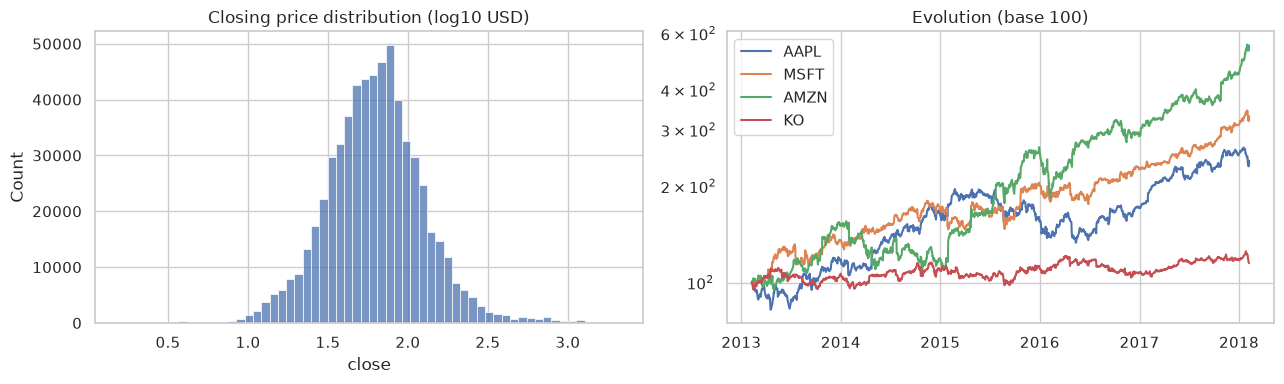

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log10(data['close']), bins=60, ax=ax[0]); ax[0].set_title('Closing price distribution (log10 USD)')
for tk in ['AAPL', 'MSFT', 'AMZN', 'KO']:
    s = data[data['Name'] == tk].set_index('date')['close']; ax[1].plot(s / s.iloc[0] * 100, label=tk)
ax[1].set_yscale('log'); ax[1].set_title('Evolution (base 100)'); ax[1].legend()
plt.tight_layout(); plt.show()

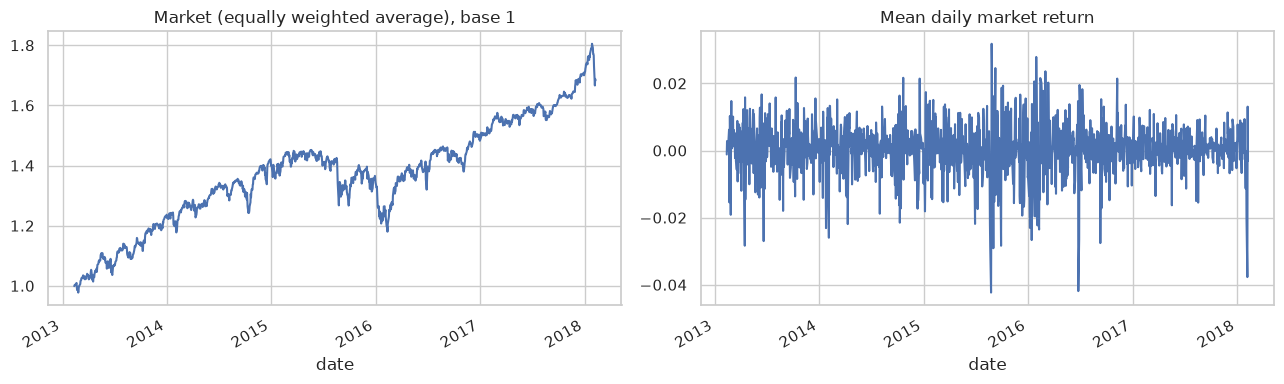

Worst 3 market days:
date
2015-08-24   -0.0423
2016-06-24   -0.0419
2018-02-05   -0.0377


In [5]:
data['ret'] = data.groupby('Name')['close'].transform(lambda c: np.log(c).diff())
market = data.groupby('date')['ret'].mean()            # mean daily return of all stocks
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
market.cumsum().apply(np.exp).plot(ax=ax[0], title='Market (equally weighted average), base 1')
market.plot(ax=ax[1], title='Mean daily market return')
plt.tight_layout(); plt.show()
print('Worst 3 market days:'); print(market.nsmallest(3).round(4).to_string())

In [6]:
ext = data.loc[data['ret'].abs().nlargest(8).index, ['Name', 'date', 'close', 'ret']]
ext['ret'] = ext['ret'].round(3); ext['date'] = ext['date'].dt.date
print('Most extreme daily moves:'); print(ext.to_string(index=False))
print('\nDays with |return| > 0.4:', (data['ret'].abs() > 0.4).sum(), 'of', len(data))

Most extreme daily moves:
 Name       date  close    ret
   NI 2015-07-02 16.990 -0.984
 EBAY 2015-07-20 28.570 -0.842
DISCK 2014-08-07 39.780 -0.714
DISCA 2014-08-07 40.975 -0.706
  LNT 2016-05-20 35.910  0.698
  LNT 2016-05-19 17.870 -0.682
  BAX 2015-07-01 38.860 -0.588
 VRTX 2013-04-19 85.600  0.482

Days with |return| > 0.4: 14 of 619040


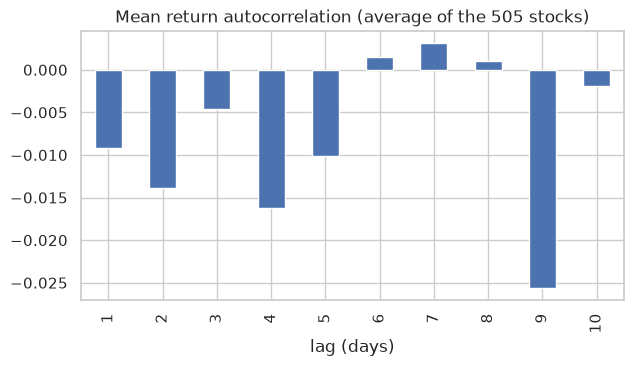

In [7]:
acf = pd.concat([data.groupby('Name')['ret'].apply(lambda r: r.autocorr(l)) for l in range(1, 11)], axis=1)
acf.columns = range(1, 11)
acf.mean().plot.bar(figsize=(7, 3.5), title='Mean return autocorrelation (average of the 505 stocks)')
plt.xlabel('lag (days)'); plt.show()

**Findings**
- Prices are not adjusted for corporate events: jumps of more than 40% in one day (e.g. eBay in 2015 because of the PayPal spin-off, or *splits*) **are not market moves**. They are identified and **excluded from training** together with the following 30 days, whose features would be contaminated.
- Only `open/high/low` have a few nulls and they are not used as input; `close` is complete.
- Some stocks have a short history (they joined the index after 2013), so at least 31 days are needed to predict them.
- The mean autocorrelation of returns is practically zero: very little predictive signal is anticipated.
- The final stretch of the dataset includes the February 2018 sell-off, a volatility regime change that will fall in the test set.

## 4. Model (2 pts)

**Preprocessing:** features derived from the closing prices of each stock (`build_features`) and standardization inside a `Pipeline`. Rows contaminated by corporate events are excluded.

**Temporal split (dates are not shuffled):**
- *Training:* up to 2017-02-07 (4 years).
- *Validation:* 2017-02-08 – 2017-08-07 (model selection).
- *Test:* 2017-08-08 – end of the dataset, used once at the end.

**Algorithms compared:** baselines (*naive* = return 0, and *drift* = mean return) and three ML models — Ridge, Random Forest and Gradient Boosting (`HistGradientBoostingRegressor`) — tuned with `GridSearchCV` and `TimeSeriesSplit` (rows are sorted by date, so every fold validates on the future of its training data).

In [8]:
THRESHOLD = 0.4        # a larger jump is considered a corporate event, not a market move
parts = []
for tk, g in data.groupby('Name'):
    c = g['close'].reset_index(drop=True)
    F = build_features(c)
    r = np.log(c).diff()
    F['y'] = np.log(c.shift(-1) / c)                       # tomorrow's return (target)
    F['next_close'] = c.shift(-1); F['close'] = c
    F['jump'] = (r.abs().rolling(31, min_periods=1).max() > THRESHOLD) | (F['y'].abs() > THRESHOLD)
    F['Name'] = tk; F['date'] = g['date'].values
    parts.append(F)
D = pd.concat(parts, ignore_index=True).sort_values('date', kind='stable').reset_index(drop=True)

complete = D[FEATURES + ['y']].notna().all(axis=1)
valid = complete & ~D['jump']
print(f'Rows with features and target: {complete.sum():,} | excluded because of corporate events: {(complete & D["jump"]).sum():,}')

val_date, test_date = pd.Timestamp('2017-02-08'), pd.Timestamp('2017-08-08')
m_trn = valid & (D['date'] < val_date)
m_val = valid & (D['date'] >= val_date) & (D['date'] < test_date)
m_tst = valid & (D['date'] >= test_date)
print(f'training {m_trn.sum():,} | validation {m_val.sum():,} | test {m_tst.sum():,} rows')
X, y = D[FEATURES], D['y']

Rows with features and target: 603,385 | excluded because of corporate events: 387
training 477,030 | validation 62,552 | test 63,416 rows


In [9]:
tscv = TimeSeriesSplit(n_splits=3)
def pipe(est): return Pipeline([('scaler', StandardScaler()), ('model', est)])

grids = {
    'Ridge': (pipe(Ridge()), {'model__alpha': [10, 100, 1000]}),
    'Random Forest': (pipe(RandomForestRegressor(n_estimators=60, max_samples=0.03, max_depth=8,
                                                 random_state=RANDOM_STATE, n_jobs=-1)),
                      {'model__min_samples_leaf': [200, 500]}),
    'Gradient Boosting': (pipe(HistGradientBoostingRegressor(max_iter=150, min_samples_leaf=500, l2_regularization=10,
                                                             random_state=RANDOM_STATE)),
                          {'model__max_depth': [3, 5], 'model__learning_rate': [0.03, 0.1]}),
}
best = {}
for name, (p, grid) in grids.items():
    gs = GridSearchCV(p, grid, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X[m_trn], y[m_trn])
    best[name] = gs
    print(f'{name:18s} best parameters: {gs.best_params_}  | CV RMSE (return): {-gs.best_score_:.5f}')

Ridge              best parameters: {'model__alpha': 1000}  | CV RMSE (return): 0.01662


Random Forest      best parameters: {'model__min_samples_leaf': 500}  | CV RMSE (return): 0.01660


Gradient Boosting  best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 3}  | CV RMSE (return): 0.01660


In [10]:
baselines = {
    'Naive baseline (tomorrow = today)': DummyRegressor(strategy='constant', constant=0.0).fit(X[m_trn], y[m_trn]),
    'Drift baseline (mean return)': DummyRegressor(strategy='mean').fit(X[m_trn], y[m_trn]),
}
models = {**baselines, **{n: gs.best_estimator_ for n, gs in best.items()}}

## 5. Evaluation (1 pt)
The predicted price is rebuilt as `close_today · exp(return)`. An *R² of the return* close to 0 or negative means the model does not explain the daily variation. Directional accuracy is not defined for the naive baseline (it always predicts "no change").

In [11]:
def evaluate(model, mask):
    p = model.predict(X[mask]); actual = D.loc[mask, 'next_close'].values; pred = D.loc[mask, 'close'].values * np.exp(p)
    yy = y[mask].values
    return {'RMSE (USD)': np.sqrt(mean_squared_error(actual, pred)), 'MAE (USD)': mean_absolute_error(actual, pred),
            'MAPE (%)': np.mean(np.abs(actual - pred) / actual) * 100, 'Return RMSE': np.sqrt(mean_squared_error(yy, p)),
            'Return R²': r2_score(yy, p),
            'Directional accuracy': np.mean(np.sign(p) == np.sign(yy)) if np.any(p != 0) else np.nan}

val_table  = pd.DataFrame({n: evaluate(m, m_val) for n, m in models.items()}).T
test_table = pd.DataFrame({n: evaluate(m, m_tst) for n, m in models.items()}).T
fmt = {'RMSE (USD)': '{:.3f}', 'MAE (USD)': '{:.3f}', 'MAPE (%)': '{:.3f}', 'Return RMSE': '{:.5f}', 'Return R²': '{:.5f}', 'Directional accuracy': '{:.3f}'}
print('VALIDATION (2017-02-08 – 2017-08-07)'); display(val_table.style.format(fmt))
print('TEST (2017-08-08 – end of the dataset, includes the February 2018 sell-off)'); display(test_table.style.format(fmt))

VALIDATION (2017-02-08 – 2017-08-07)


,RMSE (USD),MAE (USD),MAPE (%),Return RMSE,Return R²,Directional accuracy
Naive baseline (tomorrow = today),1.841,0.803,0.883,0.01361,-0.00079,nan
Drift baseline (mean return),1.837,0.801,0.882,0.01360,-0.00000,0.524
Ridge,1.841,0.804,0.884,0.01362,-0.00304,0.502
Random Forest,1.840,0.803,0.883,0.01361,-0.00069,0.509
Gradient Boosting,1.837,0.801,0.882,0.01360,0.00003,0.524


TEST (2017-08-08 – end of the dataset, includes the February 2018 sell-off)


,RMSE (USD),MAE (USD),MAPE (%),Return RMSE,Return R²,Directional accuracy
Naive baseline (tomorrow = today),2.543,1.003,1.003,0.01570,-0.00083,nan
Drift baseline (mean return),2.541,1.001,1.001,0.01569,-0.00001,0.531
Ridge,2.541,1.002,1.003,0.01571,-0.00240,0.505
Random Forest,2.545,1.005,1.005,0.01573,-0.00415,0.501
Gradient Boosting,2.543,1.002,1.002,0.01571,-0.00166,0.531


Selected model (lowest validation return RMSE among the ML models): Gradient Boosting


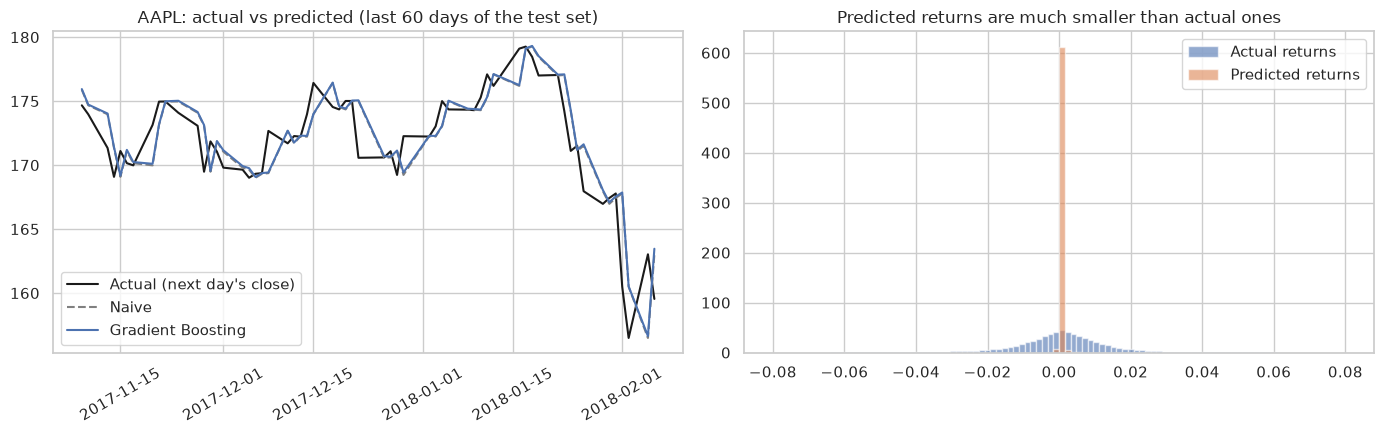

Standard deviation: actual 0.0157 | predicted 0.0003


In [12]:
ml = list(best)
chosen = min(ml, key=lambda n: val_table.loc[n, 'Return RMSE'])
print('Selected model (lowest validation return RMSE among the ML models):', chosen)

# Example: AAPL over the last 60 days of the test set
m_ap = m_tst & (D['Name'] == 'AAPL'); sub = D[m_ap].tail(60)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(sub['date'], sub['next_close'], 'k', label="Actual (next day's close)")
ax[0].plot(sub['date'], sub['close'], '--', color='gray', label='Naive')
ax[0].plot(sub['date'], sub['close'] * np.exp(models[chosen].predict(sub[FEATURES])), label=chosen)
ax[0].set_title('AAPL: actual vs predicted (last 60 days of the test set)'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=30)
pred_t = models[chosen].predict(X[m_tst])
ax[1].hist(y[m_tst], bins=100, alpha=.6, label='Actual returns', range=(-0.08, 0.08), density=True)
ax[1].hist(pred_t, bins=100, alpha=.6, label='Predicted returns', range=(-0.08, 0.08), density=True)
ax[1].set_title('Predicted returns are much smaller than actual ones'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'Standard deviation: actual {y[m_tst].std():.4f} | predicted {pred_t.std():.4f}')

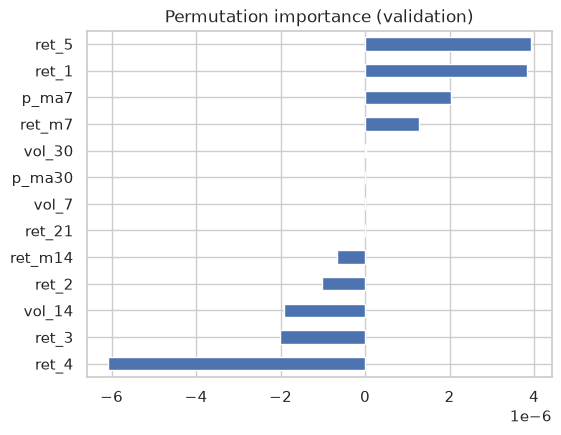

In [13]:
sample = np.random.RandomState(RANDOM_STATE).choice(np.where(m_val)[0], 20000, replace=False)
pi = permutation_importance(models[chosen], X.iloc[sample], y.iloc[sample], scoring='neg_root_mean_squared_error',
                            n_repeats=3, random_state=RANDOM_STATE)
pd.Series(pi.importances_mean, index=FEATURES).sort_values().plot.barh(figsize=(6, 4.5), title='Permutation importance (validation)')
plt.show()

## 6. Conclusion (0.5 pt)

**How well does it work?** No model clearly beats the baseline. On validation the return RMSE is 0.0136 for all of them, and the MAPE stays between 0.882% and 0.884% (naive: 0.883%; Gradient Boosting: 0.882%). On the test set the MAPE is ~1.00% for all (naive 1.003%, Gradient Boosting 1.002%, Random Forest 1.004%) and the *return R²* is zero or negative (Gradient Boosting: −0.002). In other words, with these features the daily variation of a stock cannot be explained.

**What was learned**
- The chosen model (Gradient Boosting) predicts almost constant returns: its standard deviation is 0.0004 versus 0.0157 for the actual returns. In practice it is equivalent to the *drift* baseline (the historical mean return), which is why the API returns the current price plus an adjustment between 0% and 0.4%.
- The directional accuracy (~53%) is not skill: it matches the drift baseline, which always predicts "up", because the market rose in that period.
- The test error is larger than the validation error (MAPE 1.00% vs 0.88%) for **all** models, including the naive one. It is due to higher volatility in the final period (it includes the February 2018 sell-off), not to the model failing more.
- The result is consistent with the almost null autocorrelation observed in the exploration, with the efficient market hypothesis (Fama, 1970) and with the scarce predictability reported in the literature (Gu et al., 2020).
- Excluding corporate events (14 jumps larger than 40% in one day, 387 rows with their windows) avoided training on moves that are not market moves.

**Chosen model:** Gradient Boosting (lowest validation return RMSE among the ML models), retrained with all the data for the API.

**Limitations and possible improvements:** add information that is not in the stock's own price (volume, variables of the whole market or sector, fundamentals, news sentiment), try sequence models (LSTM, Fischer and Krauss, 2018), predict **volatility** —much more predictable than price— or an interval instead of a single value, and use a cross-sectional ranking approach instead of absolute prices. Also, the dataset ends on 2018-02-07, so "tomorrow" in the API is 2018-02-08, unless recent closes are sent with `recent_closes`.

## Export the model
The chosen model is **retrained with all the data** (training + validation + test) and saved together with the last 60 closing prices of each stock, so the API can predict "tomorrow" without receiving data.

In [14]:
final_model = clone(models[chosen]).fit(X[valid], y[valid])

history = {tk: {'last_date': g['date'].iloc[-1].date().isoformat(), 'closes': g['close'].tail(60).round(4).tolist()}
           for tk, g in data.groupby('Name')}
bundle = {'pipeline': final_model, 'model': chosen, 'features': FEATURES, 'sklearn': sklearn.__version__,
          'history': history,
          'validation_metrics': val_table.loc[chosen].to_dict(), 'test_metrics': test_table.loc[chosen].to_dict()}
joblib.dump(bundle, '../models/stocks.joblib', compress=3)
print(f'Saved ../models/stocks.joblib | {len(history)} stocks | last data point: {max(h["last_date"] for h in history.values())}')

# API contract check
from predictors.stocks import predict
print(predict({'ticker': 'AAPL'}))
res = pd.DataFrame([predict({'ticker': tk}) for tk in history if len(history[tk]['closes']) >= 31])
print(f'\n{len(res)} stocks predicted | mean change {res.change_pct.mean():.3f} % | range [{res.change_pct.min():.2f} %, {res.change_pct.max():.2f} %]')

Saved ../models/stocks.joblib | 505 stocks | last data point: 2018-02-07
{'ticker': 'AAPL', 'prediction': 159.6, 'unit': 'USD', 'current_price': 159.54, 'change_pct': 0.038, 'model': 'Gradient Boosting', 'note': 'Academic reference; not financial advice.', 'base_date': '2018-02-07', 'prediction_date': '2018-02-08'}



505 stocks predicted | mean change 0.081 % | range [0.00 %, 0.39 %]
